# BNB/USDT 模式发现 — 趋势底座与相对弱势反转

**目的**：仿 BTC 的探索流程，先找 BNB 自己的价格形态，再检查它是否能形成可交易规则；不是把 BTC 的 SMA50 参数直接搬过来，也不训练 PPO。

已知背景（截至 2026-09-03 的旧研究）：SMA200 趋势门跨资产较稳；BTC 的 SMA50 退出在 BNB 上未达到回撤验收线；funding/OI/持仓分歧方向已经失败。本 notebook 因此聚焦**价格与 BTC 参照所能提供的新信息**。

## 研究口径

- 数据：`public.crypto_kline_1d`，UTC 日线；BNB/BTC 用于主分析，ETH/SOL 只作固定规则兄弟资产检验。
- 最后完整日：**2026-10-25**。日线视图没有 `is_closed`，所以显式用 `END = 2026-10-26` 排除未完成日。
- T 日收盘得到信号，`shift(1)` 后吃下一根 close-to-close 收益；只做多/空仓，无杠杆。
- 成本：仓位每变化 100% 收 0.1%（换仓成本近似从对数收益扣除）。
- 探索段只到 **2026-09-03**；`2026-09-04 → 2026-10-25` 是本次新留出段，候选固定后才打开。
- 旧三段沿用 BTC 研究：pre_val / val / old_test。old_test 对既有均线规则不是新数据，但对本 notebook 新提出的相对弱势规则未参与筛选。
- 本 notebook 是模式研究，不是生产上线验收；短留出段只作一致性检查。

## 0. 读取、特征与统一回测器

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import spearmanr

ROOT = Path.cwd()
if not (ROOT / 'utils').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from utils.db import read_ohlcv

START = '2021-01-01'
END = '2026-10-26'  # exclusive; last complete UTC day = 2026-10-25
OLD_END = '2026-09-04'
PERIODS = {
    'pre_val': ('2021-08-01', '2024-10-01'),
    'val': ('2024-10-01', '2026-04-13'),
    'old_test': ('2026-04-13', OLD_END),
}
HOLDOUT = (OLD_END, END)
ASSETS = ['BTC', 'BNB', 'ETH', 'SOL']

def load_close(asset):
    raw = read_ohlcv(
        f'{asset}/USDT', start=f'{START}T00:00:00+00:00',
        end=f'{END}T00:00:00+00:00', table='public.crypto_kline_1d',
        only_closed=False,
    )
    raw['timestamp'] = pd.to_datetime(raw['timestamp'], utc=True)
    return raw.set_index('timestamp')['close'].astype(float).rename(asset)

px = pd.concat([load_close(a) for a in ASSETS], axis=1).sort_index()
assert px.index.is_unique and px.index.is_monotonic_increasing
expected = pd.date_range(px.index.min(), px.index.max(), freq='D', tz='UTC')
missing = expected.difference(px.index)
print(f'rows={len(px):,}; {px.index.min().date()} → {px.index.max().date()}; missing UTC days={len(missing)}')
print('last rows:')
display(px.tail(3).round(2))

bnb, btc = px['BNB'], px['BTC']
log_ret = np.log(bnb).diff()
ratio = bnb / btc
gate200 = bnb > bnb.rolling(200).mean()
rel60 = np.log(ratio / ratio.shift(60))
rel60_signal = rel60 < 0

PERIOD_LABELS = {'pre_val': '2021-08→2024-09', 'val': '2024-10→2026-04', 'old_test': '2026-04→2026-09', 'holdout': '2026-09→2026-10'}

def strategy_returns(signal, asset='BNB', cost=0.001):
    signal = signal.reindex(px.index).fillna(False).astype(float)
    position = signal.shift(1).fillna(0.0)
    turnover = position.diff().abs().fillna(position)
    ret = position * np.log(px[asset]).diff() - cost * turnover
    return ret.rename('log_ret'), position.rename('position')

def metrics(ret, position, start, end):
    mask = (ret.index >= start) & (ret.index < end)
    r, p = ret[mask], position[mask]
    curve = pd.concat([pd.Series([0.0]), r.cumsum().reset_index(drop=True)], ignore_index=True)
    dd = curve - curve.cummax()
    years = (pd.Timestamp(end).tz_localize(None) - pd.Timestamp(start).tz_localize(None)).days / 365.25
    return {
        'return': np.exp(r.sum()) - 1,
        'mdd': np.exp(dd.min()) - 1,
        'switches_per_year': p.diff().abs().fillna(p).sum() / years,
        'exposure': p.mean(),
    }

def metrics_table(signals, periods=PERIODS, cost=0.001):
    rows = []
    for period, (start, end) in periods.items():
        for name, signal in signals.items():
            ret, pos = strategy_returns(signal, cost=cost)
            rows.append({'period': period, 'strategy': name, **metrics(ret, pos, start, end)})
    out = pd.DataFrame(rows).set_index(['period', 'strategy'])
    return out.style.format({'return': '{:+.2%}'.format, 'mdd': '{:.2%}'.format,
                             'switches_per_year': '{:.1f}'.format, 'exposure': '{:.1%}'.format})

baselines = {
    'buy_hold': pd.Series(True, index=px.index),
    'gate200': gate200,
    'rel60_reversal': rel60_signal,
}

rows=2,124; 2021-01-01 → 2026-10-25; missing UTC days=0
last rows:


,BTC,BNB,ETH,SOL
timestamp,,,,
2026-10-23 00:00:00+00:00,81189.43,739.59,2387.60,102.85
2026-10-24 00:00:00+00:00,80888.16,740.00,2358.82,102.38
2026-10-25 00:00:00+00:00,80154.09,738.69,2329.87,101.40


## 1. 先看底座与回撤 episode

BNB 是长趋势与深回撤交替的资产。规则是否有效，首先要看它在大回撤里做了什么，而不是只看全样本收益。

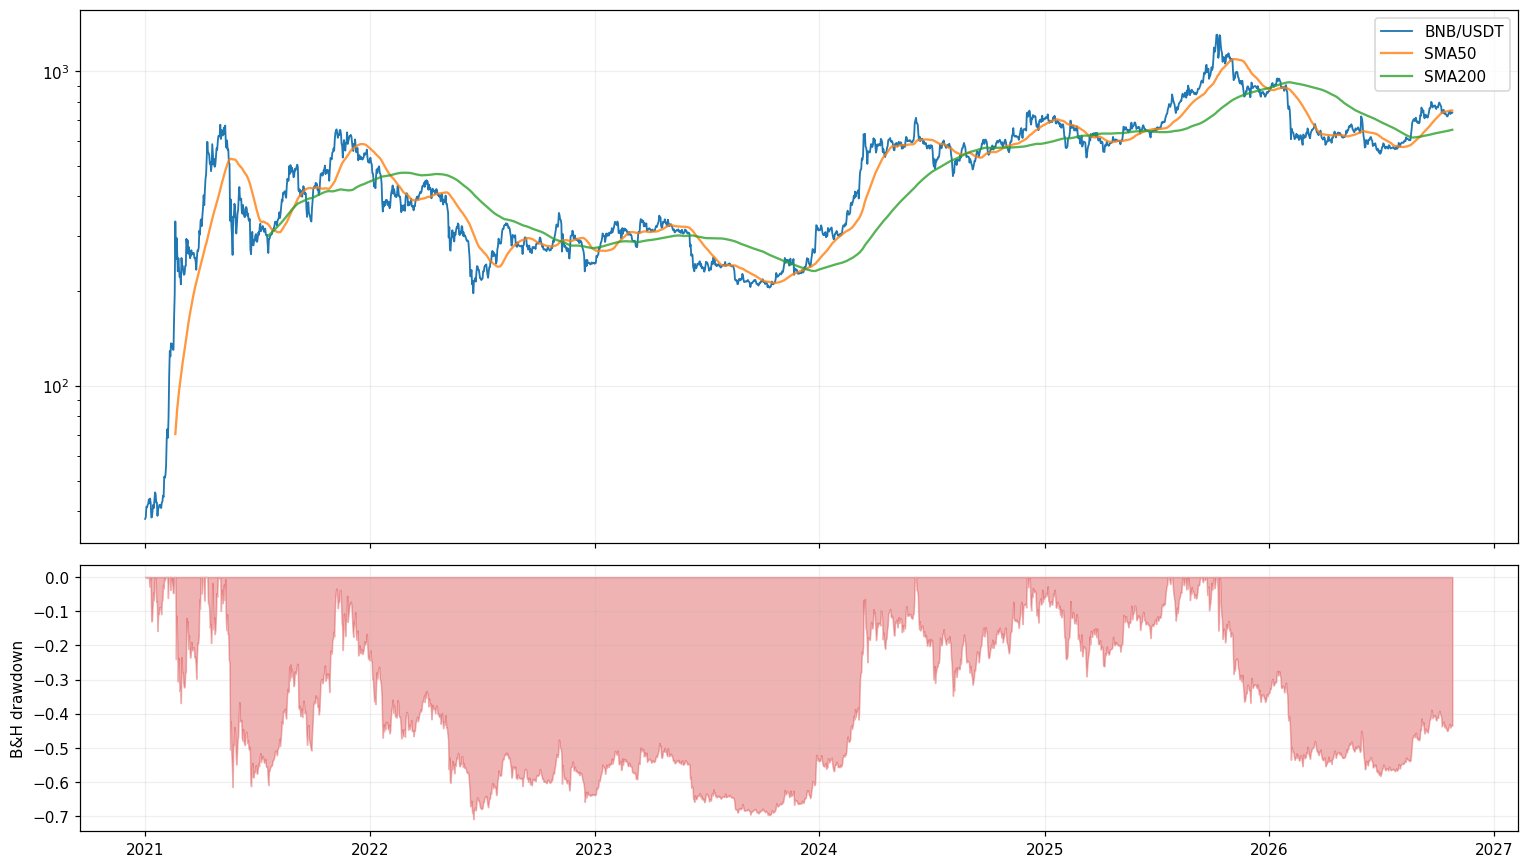

,peak,trough,recovery,depth,days_to_trough
13,2021-05-03 00:00:00+00:00,2022-06-18 00:00:00+00:00,2024-06-04 00:00:00+00:00,-70.9%,411
27,2025-10-08 00:00:00+00:00,2026-06-30 00:00:00+00:00,NaT,-58.2%,265
8,2021-02-19 00:00:00+00:00,2021-02-28 00:00:00+00:00,2021-04-01 00:00:00+00:00,-36.9%,9
14,2024-06-06 00:00:00+00:00,2024-08-05 00:00:00+00:00,2024-12-03 00:00:00+00:00,-34.7%,60
16,2024-12-07 00:00:00+00:00,2025-03-10 00:00:00+00:00,2025-07-20 00:00:00+00:00,-29.1%,93
11,2021-04-12 00:00:00+00:00,2021-04-18 00:00:00+00:00,2021-04-29 00:00:00+00:00,-19.3%,6


In [2]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True,
                         gridspec_kw={'height_ratios': [2, 1]})
axes[0].plot(px.index, bnb, label='BNB/USDT', lw=1.2)
axes[0].plot(px.index, bnb.rolling(50).mean(), label='SMA50', alpha=.8)
axes[0].plot(px.index, bnb.rolling(200).mean(), label='SMA200', alpha=.8)
axes[0].set_yscale('log'); axes[0].legend(); axes[0].grid(alpha=.2)
underwater = bnb / bnb.cummax() - 1
axes[1].fill_between(px.index, underwater, 0, color='tab:red', alpha=.35)
axes[1].set_ylabel('B&H drawdown'); axes[1].grid(alpha=.2)
plt.tight_layout(); plt.show()

def drawdown_episodes(price):
    dd = price / price.cummax() - 1
    active = dd < 0
    group = active.ne(active.shift()).cumsum()
    rows = []
    for _, part in dd[active].groupby(group[active]):
        trough = part.idxmin()
        end = part.index[-1]
        next_i = price.index.get_loc(end) + 1
        recovery = price.index[next_i] if next_i < len(price) else pd.NaT
        peak_i = max(0, price.index.get_loc(part.index[0]) - 1)
        peak = price.index[peak_i]
        rows.append({'peak': peak, 'trough': trough, 'recovery': recovery,
                     'depth': part.min(), 'days_to_trough': (trough - peak).days})
    return pd.DataFrame(rows).sort_values('depth')

episodes = drawdown_episodes(bnb)
display(episodes.head(6).style.format({'depth': '{:.1%}'.format}))

## 2. 条件收益：寻找 BNB 自己的形状（不看新留出段）

特征分两类：BNB 绝对趋势/动量，以及 BNB 相对 BTC 的强弱。rank IC 是特征与未来收益的 Spearman 秩相关；这里只做描述，不把许多相关数字中的最大值当结论。

重点检查：方向能否跨 pre_val / val / old_test 一致，以及 5 天和 20 天是否讲的是同一件事。

In [3]:
features = pd.DataFrame(index=px.index)
for n in [20, 50, 100, 200]:
    features[f'dist_sma{n}'] = bnb / bnb.rolling(n).mean() - 1
for n in [20, 60, 120]:
    features[f'mom{n}'] = np.log(bnb / bnb.shift(n))
for n in [20, 60]:
    features[f'rel_mom{n}'] = np.log(ratio / ratio.shift(n))
features['rel_dist50'] = ratio / ratio.rolling(50).mean() - 1
features['rvol20'] = log_ret.rolling(20).std() * np.sqrt(365)
features['dd60'] = bnb / bnb.rolling(60).max() - 1
delta = bnb.diff()
up = delta.clip(lower=0).ewm(alpha=1/14, adjust=False).mean()
down = (-delta.clip(upper=0)).ewm(alpha=1/14, adjust=False).mean()
features['rsi14'] = 100 - 100 / (1 + up / down)

def ic_table(target, horizon):
    rows = []
    for name in features:
        row = {'feature': name}
        for period, (start, end) in PERIODS.items():
            mask = (px.index >= start) & (px.index < end)
            x, y = features.loc[mask, name], target[mask]
            ok = x.notna() & y.notna()
            row[period] = spearmanr(x[ok], y[ok]).statistic
        rows.append(row)
    return pd.DataFrame(rows).set_index('feature')

for horizon in [5, 20]:
    forward = np.log(bnb.shift(-horizon) / bnb)
    print(f'BNB/USDT forward {horizon}d rank IC — old samples only')
    display(ic_table(forward, horizon).style.format('{:+.3f}'))

BNB/USDT forward 5d rank IC — old samples only
BNB/USDT forward 20d rank IC — old samples only


,pre_val,val,old_test
feature,,,
dist_sma20,-0.002,-0.036,-0.048
dist_sma50,+0.006,+0.031,+0.105
dist_sma100,-0.032,+0.039,-0.005
dist_sma200,-0.022,-0.040,+0.061
mom20,-0.028,-0.018,+0.068
mom60,-0.058,+0.045,+0.028
mom120,-0.003,+0.003,-0.001
rel_mom20,-0.121,-0.040,-0.120
rel_mom60,-0.125,-0.018,-0.197


,pre_val,val,old_test
feature,,,
dist_sma20,-0.029,-0.011,+0.327
dist_sma50,-0.033,+0.068,+0.270
dist_sma100,-0.044,+0.084,-0.016
dist_sma200,-0.052,-0.071,+0.263
mom20,-0.009,+0.059,+0.366
mom60,-0.055,+0.062,-0.044
mom120,+0.027,-0.032,+0.358
rel_mom20,-0.309,-0.165,-0.352
rel_mom60,-0.233,-0.113,-0.212


### 2.1 不要把绝对收益反转误称为“必然跑赢 BTC”

`rel_mom = BNB过去收益 − BTC过去收益` 能预测 BNB 绝对收益，不等于能预测 BNB/BTC 比值。下面把预测目标换成未来相对收益；如果方向不稳，就只能提出 BNB/USDT 多空仓候选，不能提出 BNB/BTC 轮动结论。

In [4]:
rows = []
for n in [10, 20, 40, 60]:
    x = np.log(ratio / ratio.shift(n))
    for horizon in [5, 20]:
        y_abs = np.log(bnb.shift(-horizon) / bnb)
        y_rel = np.log(ratio.shift(-horizon) / ratio)
        row = {'lookback': n, 'horizon': horizon}
        for period, (start, end) in PERIODS.items():
            mask = (px.index >= start) & (px.index < end) & x.notna() & y_abs.notna()
            row[f'{period}_abs'] = spearmanr(x[mask], y_abs[mask]).statistic
            row[f'{period}_relative'] = spearmanr(x[mask], y_rel[mask]).statistic
        rows.append(row)
ic_split = pd.DataFrame(rows).set_index(['lookback', 'horizon'])
display(ic_split.style.format('{:+.3f}'))
print('阅读：绝对收益 IC 的方向较一致；相对收益 IC 在 pre_val/val 经常反号，不做 BTC 轮动结论。')

阅读：绝对收益 IC 的方向较一致；相对收益 IC 在 pre_val/val 经常反号，不做 BTC 轮动结论。


## 3. 候选规则与旧样本结果

从 §2 得到的候选是 **相对弱势反转**，不是趋势延续：

> `rel60 = log[(BNB/BTC)_t / (BNB/BTC)_{t-60}]`。若 `rel60 < 0`，下一日持有 100% BNB；否则空仓。

它回答的是“BNB 过去 60 天跑输 BTC 后，BNB/USDT 是否更容易修复”，并不预测它一定跑赢 BTC。60 天是旧样本中的主变体；20/30/40/50/80/90/120 天邻域必须一起展示。

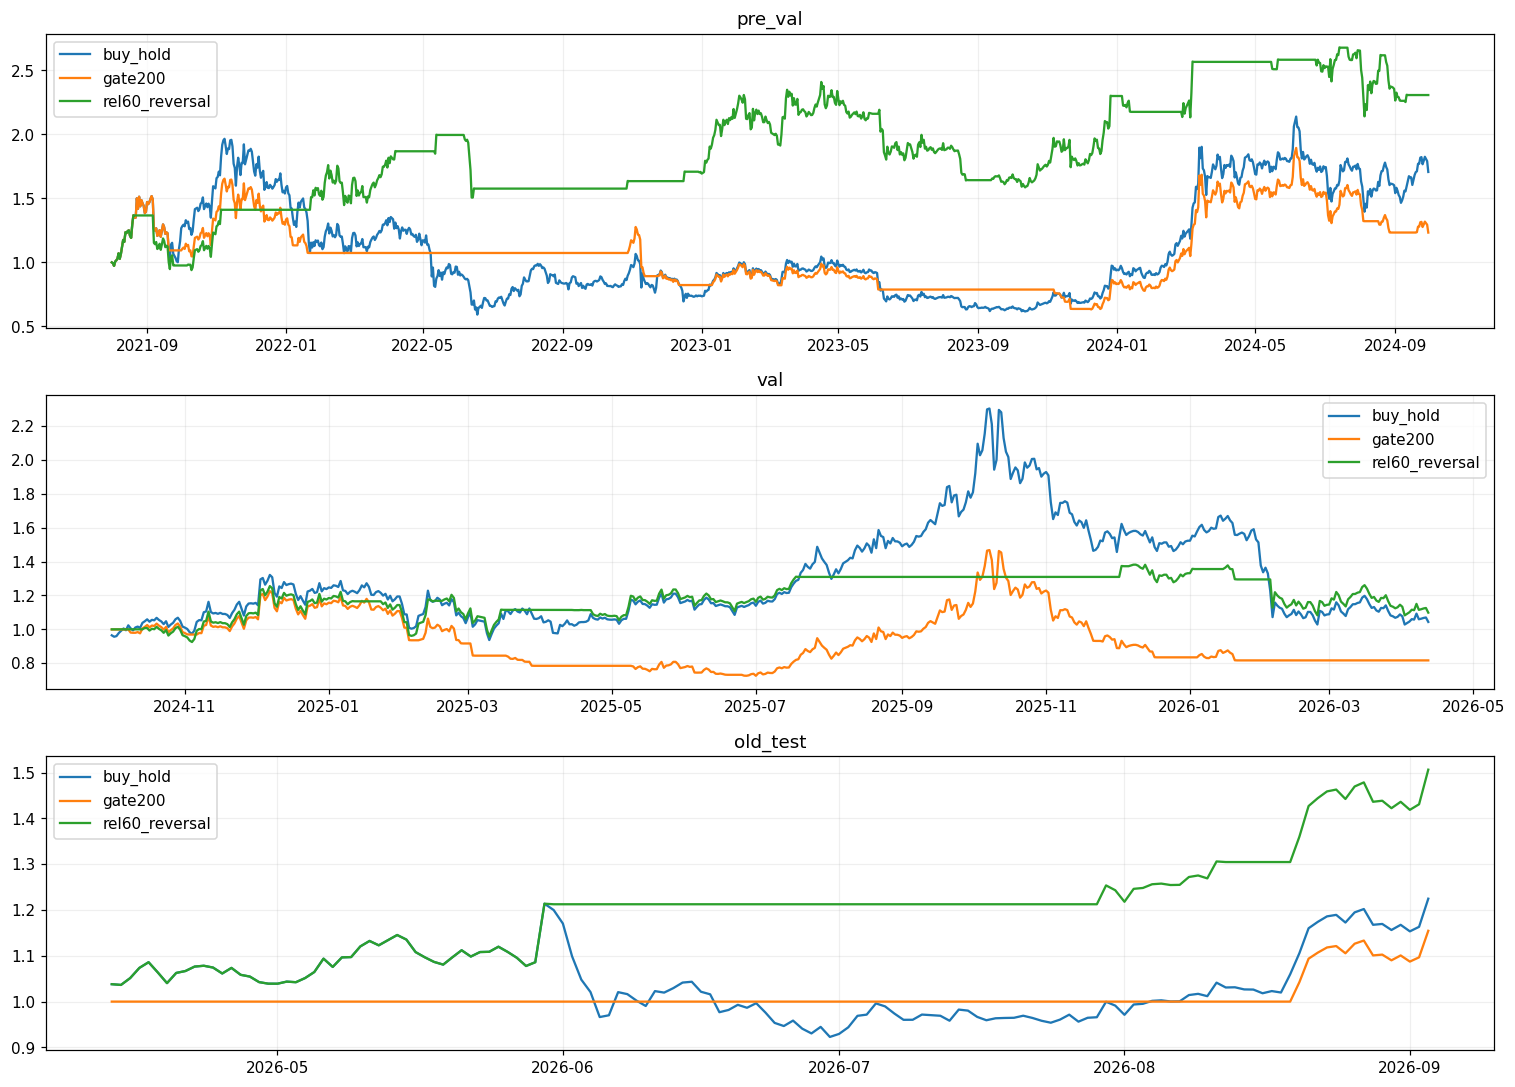

In [5]:
display(metrics_table(baselines))

all_periods = {**PERIODS, 'holdout': HOLDOUT}
fig, axes = plt.subplots(3, 1, figsize=(14, 10))
for ax, (period, (start, end)) in zip(axes, PERIODS.items()):
    for name, signal in baselines.items():
        ret, _ = strategy_returns(signal)
        curve = np.exp(ret[(ret.index >= start) & (ret.index < end)].cumsum())
        ax.plot(curve.index, curve, label=name)
    ax.set_title(period); ax.grid(alpha=.2); ax.legend()
plt.tight_layout(); plt.show()

### 3.1 参数邻域：防止只挑最好看的长度

In [6]:
rows = []
for n in [20, 30, 40, 50, 60, 80, 90, 120]:
    signal = np.log(ratio / ratio.shift(n)) < 0
    ret, pos = strategy_returns(signal)
    row = {'lookback': n}
    for period, (start, end) in PERIODS.items():
        m = metrics(ret, pos, start, end)
        row[f'{period}_return'] = m['return']
        row[f'{period}_mdd'] = m['mdd']
        row[f'{period}_switches_y'] = m['switches_per_year']
    rows.append(row)
plateau = pd.DataFrame(rows).set_index('lookback')
display(plateau.style.format({c: '{:+.1%}'.format for c in plateau if c.endswith('return')} |
                             {c: '{:.1%}'.format for c in plateau if c.endswith('mdd')} |
                             {c: '{:.1f}'.format for c in plateau if c.endswith('switches_y')}))
print('阅读重点：30–90 天的回撤方向是否一致；120 天在 old_test 已破坏平台，不能无限外推。')

阅读重点：30–90 天的回撤方向是否一致；120 天在 old_test 已破坏平台，不能无限外推。


,pre_val_return,pre_val_mdd,pre_val_switches_y,val_return,val_mdd,val_switches_y,old_test_return,old_test_mdd,old_test_switches_y
lookback,,,,,,,,,
20,+177.7%,-53.9%,41.4,-11.7%,-43.1%,37.2,+32.1%,-7.0%,17.8
30,+238.3%,-31.7%,29.7,+45.8%,-27.3%,33.3,+22.1%,-4.3%,33.0
40,+258.5%,-42.9%,23.7,+1.8%,-24.4%,28.1,+24.7%,-5.6%,30.4
50,+152.6%,-32.6%,22.1,+0.4%,-25.4%,22.9,+32.7%,-5.6%,12.7
60,+130.8%,-34.2%,20.8,+9.9%,-23.8%,17.6,+50.6%,-5.9%,12.7
80,+102.4%,-43.7%,24.3,+18.7%,-25.1%,26.8,+45.5%,-5.9%,7.6
90,+56.5%,-44.1%,19.9,+13.6%,-24.0%,20.3,+27.4%,-5.9%,12.7
120,+251.0%,-41.0%,14.5,+23.2%,-29.1%,11.1,-5.8%,-25.8%,40.6


## 4. 稳定性检查

### 4.1 逐年：收益来自长期结构，还是单次牛市/熊市？

只展示 2022 年至 2026-09-03，避免新留出段反向参与解释。

In [7]:
year_rows = []
for year in range(2022, 2027):
    start, end = f'{year}-01-01', f'{year + 1}-01-01' if year < 2026 else OLD_END
    for name, signal in baselines.items():
        ret, pos = strategy_returns(signal)
        year_rows.append({'year': year, 'strategy': name, **metrics(ret, pos, start, end)})
yearly = pd.DataFrame(year_rows).set_index(['year', 'strategy'])
display(yearly.style.format({'return': '{:+.1%}'.format, 'mdd': '{:.1%}'.format,
                             'switches_per_year': '{:.1f}'.format, 'exposure': '{:.0%}'.format}))

### 4.2 兄弟资产：BNB 专属，还是币种普遍现象？

ETH/SOL 不重新选参数，直接套用同一个 60 天规则。若它们失败，说明不能把 BNB 结果外推成“所有山寨币都适用”。

In [8]:
rows = []
for asset in ['BNB', 'ETH', 'SOL']:
    asset_ratio = px[asset] / px['BTC']
    signal = np.log(asset_ratio / asset_ratio.shift(60)) < 0
    ret, pos = strategy_returns(signal, asset=asset)
    row = {'asset': asset}
    for period, (start, end) in PERIODS.items():
        m = metrics(ret, pos, start, end)
        row[f'{period}_return'] = m['return']
        row[f'{period}_mdd'] = m['mdd']
    rows.append(row)
siblings = pd.DataFrame(rows).set_index('asset')
display(siblings.style.format('{:+.1%}'))

,pre_val_return,pre_val_mdd,val_return,val_mdd,old_test_return,old_test_mdd
asset,,,,,,
BNB,+130.8%,-34.2%,+9.9%,-23.8%,+50.6%,-5.9%
ETH,+126.1%,-54.1%,-31.5%,-63.7%,-26.7%,-35.3%
SOL,+162.9%,-79.4%,-58.4%,-71.0%,-12.3%,-36.1%


### 4.3 成本敏感性与回撤 episode 机制

In [9]:
rows = []
for cost in [0.0, 0.001, 0.002, 0.003]:
    ret, pos = strategy_returns(rel60_signal, cost=cost)
    row = {'one_way_cost': cost}
    for period, (start, end) in PERIODS.items():
        m = metrics(ret, pos, start, end)
        row[f'{period}_return'] = m['return']
        row[f'{period}_mdd'] = m['mdd']
    rows.append(row)
cost_table = pd.DataFrame(rows).set_index('one_way_cost')
display(cost_table.style.format('{:+.2%}'))

ret60, pos60 = strategy_returns(rel60_signal)
episode_rows = []
for _, ep in episodes.head(5).iterrows():
    end = ep['recovery'] + pd.Timedelta(days=1) if pd.notna(ep['recovery']) else END
    row = {'peak': ep['peak'].date(), 'trough': ep['trough'].date(), 'bnb_episode_depth': ep['depth']}
    for name, signal in baselines.items():
        ret, pos = strategy_returns(signal)
        row[f'{name}_mdd'] = metrics(ret, pos, ep['peak'], end)['mdd']
    episode_rows.append(row)
episode_compare = pd.DataFrame(episode_rows).set_index(['peak', 'trough'])
display(episode_compare.style.format('{:.1%}'))

,pre_val_return,pre_val_mdd,val_return,val_mdd,old_test_return,old_test_mdd
one_way_cost,,,,,,
0.000000,+146.29%,-33.52%,+12.86%,-23.30%,+51.23%,-5.90%
0.001000,+130.79%,-34.18%,+9.86%,-23.76%,+50.63%,-5.90%
0.002000,+116.27%,-34.83%,+6.93%,-24.21%,+50.03%,-5.90%
0.003000,+102.66%,-35.48%,+4.08%,-24.67%,+49.43%,-5.90%


,,bnb_episode_depth,buy_hold_mdd,gate200_mdd,rel60_reversal_mdd
peak,trough,,,,
2021-05-03,2022-06-18,-70.9%,-70.9%,-61.7%,-34.2%
2025-10-08,2026-06-30,-58.2%,-58.2%,-44.4%,-21.7%
2021-02-19,2021-02-28,-36.9%,-36.9%,0.0%,0.0%
2024-06-06,2024-08-05,-34.7%,-34.7%,-36.9%,-20.4%
2024-12-07,2025-03-10,-29.1%,-29.1%,-40.8%,-23.8%


## 5. 新留出段：候选固定后只看一次

主变体与比较基准在看本节结果前已经固定：`rel60 < 0`、T+1、0.1% 成本。40/80 天只用于检查邻域，不允许用它们替换主变体。

短段没有足够独立回撤事件，因此即使结果好也只记为“方向一致”，不记为生产 PASS。

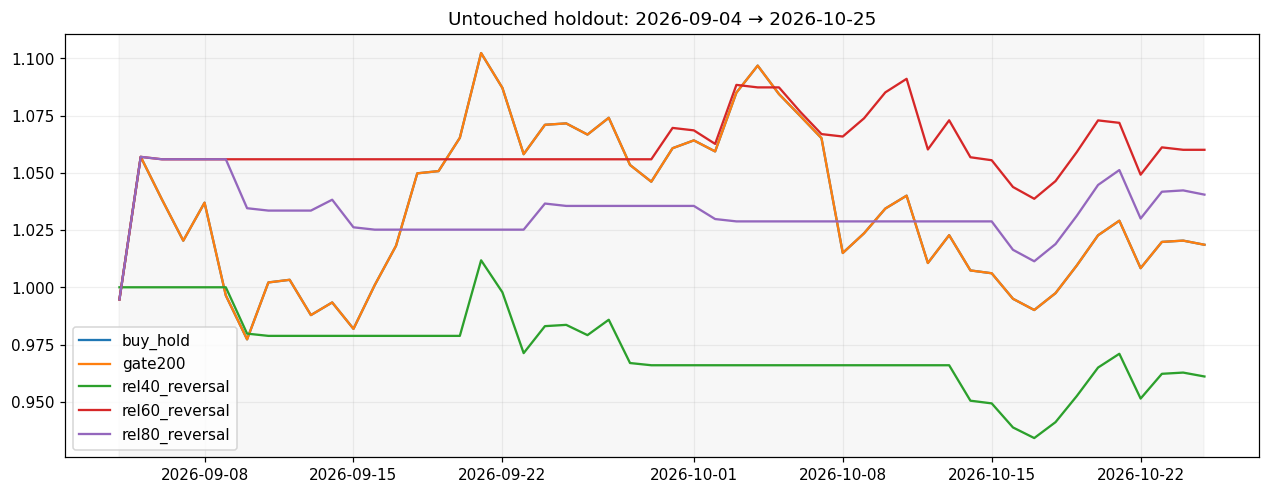

In [10]:
holdout_signals = {
    'buy_hold': baselines['buy_hold'],
    'gate200': baselines['gate200'],
    'rel40_reversal': np.log(ratio / ratio.shift(40)) < 0,
    'rel60_reversal': rel60_signal,
    'rel80_reversal': np.log(ratio / ratio.shift(80)) < 0,
}
display(metrics_table(holdout_signals, periods={'holdout': HOLDOUT}))
fig, ax = plt.subplots(figsize=(14, 5))
for name, signal in holdout_signals.items():
    ret, _ = strategy_returns(signal)
    curve = np.exp(ret[(ret.index >= HOLDOUT[0]) & (ret.index < HOLDOUT[1])].cumsum())
    ax.plot(curve.index, curve, label=name)
ax.axvspan(pd.Timestamp('2026-09-04', tz='UTC'), px.index.max(), color='grey', alpha=.06)
ax.set_title('Untouched holdout: 2026-09-04 → 2026-10-25')
ax.grid(alpha=.2); ax.legend(); plt.show()

## 6. 最新状态与结论

信号仅用于研究跟踪，不构成投资建议。T 日信号在下一交易日生效。

In [11]:
latest = px.index.max()
latest_view = pd.DataFrame({
    'value': {
        'date': str(latest.date()),
        'BNB_close': bnb.loc[latest],
        'BTC_close': btc.loc[latest],
        'BNB_60d_return': bnb.loc[latest] / bnb.shift(60).loc[latest] - 1,
        'BTC_60d_return': btc.loc[latest] / btc.shift(60).loc[latest] - 1,
        'rel60_log': rel60.loc[latest],
        'gate200_on': bool(gate200.loc[latest]),
        'rel60_hold_bnb_next_day': bool(rel60_signal.loc[latest]),
    }
})
display(latest_view)

,value
date,2026-10-25
BNB_close,738.69
BTC_close,80154.09
BNB_60d_return,0.044055
BTC_60d_return,0.014304
rel60_log,0.02891
gate200_on,True
rel60_hold_bnb_next_day,False


## 7. 观察记录（看完旧样本后、打开新留出段前登记的口径）

| 项 | 登记 |
|---|---|
| 模式 | BNB 过去 60 天跑输 BTC 后，BNB/USDT 后续绝对收益偏修复；不是 BNB/BTC 相对收益预测 |
| 主规则 | `rel60 < 0 → 次日 100% BNB，否则 0%` |
| 邻域 | 20/30/40/50/80/90/120 天必须与 60 天一起看；40/80 天进入新留出段对照 |
| 预期强项 | 降低深回撤；BNB 熊市或高波动修复期 |
| 预期代价 | 单边 BNB 牛市踏空；频繁穿越零轴时换手上升 |
| 反证 | 新留出段回撤不改善；邻域方向散乱；成本稍升即失效；兄弟资产上被当作普适规律外推 |
| 当前定位 | BNB 专属、偏防守的研究候选；不是 BTC SMA200 底座的替代品，也未达到生产上线证据标准 |

### 最终阅读要点

1. **趋势门仍是底座**：旧研究已支持 SMA200 的跨资产稳定性；本 notebook 没有推翻它。
2. **新发现的候选是相对弱势反转**：它在 BNB 旧样本和本次短留出段呈现防守价值，但收益对邻域和行情仍有敏感性。
3. **不是通用山寨币规律**：ETH/SOL 固定规则检验失败，禁止直接外推。
4. **不是 BTC 轮动信号**：未来相对收益 IC 不稳定，不能说“跑输后就会跑赢”。
5. 下一步若继续，应只做固定规则模拟盘/前向记录，不再根据这 52 天调 60 天参数；至少积累更多独立回撤与趋势 episode 后再评审。